# 03 — Modeling

Compares a simple 2-feature linear model against a 6-feature Random Forest for
predicting `target_conversion_ratio`, using Leave-One-Out Cross-Validation
(appropriate given the small sample size — 28-35 states).

**Result found in the original analysis:** the simple linear model
(tariff growth + irradiance) outperformed the Random Forest — with this few
rows, more features caused overfitting, not better generalization.

**Run `01_panel_build.ipynb` and `02_eda.ipynb` first.**

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import LeaveOneOut, cross_val_score

PROCESSED = Path("../data/processed")
df = pd.read_csv(PROCESSED / "modeling_table.csv")
df["tariff_growth_pct"] = (
    (df["tariff_domestic4kw_2025_paise_per_kwh"] - df["tariff_domestic4kw_2024_paise_per_kwh"])
    / df["tariff_domestic4kw_2024_paise_per_kwh"]
)
df.head()

,state,target_conversion_ratio,applications_aug2026,households_aug2026,installations_aug2026,tariff_domestic4kw_2024_paise_per_kwh,tariff_domestic4kw_2025_paise_per_kwh,solar_potential_6.69pct_wasteland_gw,solar_potential_3pct_wasteland_gw,tod_domestic_applicable,irradiance_annual_kwh_m2_day,mnre_nonre_capacity_2018_mw,mnre_re_capacity_2018_mw,mnre_nonre_capacity_2025_mw,mnre_re_capacity_2025_mw,tariff_growth_pct
0,Mizoram,0.9291,1552.0,1444.0,1442.0,760.0,760.0,0.61,9.09,No,4.7237,0.0,100.16,0.00,135.86,0.000000
1,Lakshadweep,0.8718,1427.0,1244.0,1244.0,508.0,588.0,NaN,NaN,NaN,NaN,0.0,3.14,26.83,4.97,0.157480
2,Chandigarh,0.8700,1638.0,1425.0,1425.0,393.0,442.0,0.02,NaN,No,NaN,0.0,26.01,0.00,78.85,0.124682
3,Tamil Nadu,0.8587,107356.0,107805.0,92186.0,569.0,596.0,204.77,17.67,No,5.2224,16638.9,13451.70,17841.38,25241.36,0.047452
4,Madhya Pradesh,0.7954,77490.0,65091.0,61634.0,964.5,977.5,318.97,61.66,No,5.2231,17065.0,6445.13,22000.00,10827.70,0.013478


## Model A — Random Forest, 6 features

In [2]:
features_6 = [
    "tariff_domestic4kw_2025_paise_per_kwh", "tariff_growth_pct",
    "solar_potential_6.69pct_wasteland_gw", "irradiance_annual_kwh_m2_day",
    "mnre_re_capacity_2025_mw", "mnre_nonre_capacity_2025_mw",
]
d6 = df[["state", "target_conversion_ratio"] + features_6].dropna()
X6, y6 = d6[features_6], d6["target_conversion_ratio"]

rf = RandomForestRegressor(n_estimators=500, max_depth=4, min_samples_leaf=2, random_state=42)
loo = LeaveOneOut()
scores_rf = cross_val_score(rf, X6, y6, cv=loo, scoring="neg_mean_absolute_error")
naive_mae_6 = np.mean(np.abs(y6 - y6.mean()))

print(f"n = {len(d6)}")
print(f"Random Forest LOO-CV MAE: {-scores_rf.mean():.4f}")
print(f"Naive baseline MAE:       {naive_mae_6:.4f}")
print(f"Improvement over naive:   {(1 - (-scores_rf.mean())/naive_mae_6)*100:.1f}%")

n = 28
Random Forest LOO-CV MAE: 0.1608
Naive baseline MAE:       0.1705
Improvement over naive:   5.7%


In [3]:
rf.fit(X6, y6)
importances = sorted(zip(features_6, rf.feature_importances_), key=lambda x: -x[1])
for feat, imp in importances:
    print(f"  {feat:45s} {imp:.3f}")

  tariff_growth_pct                             0.323
  irradiance_annual_kwh_m2_day                  0.309
  mnre_re_capacity_2025_mw                      0.155
  mnre_nonre_capacity_2025_mw                   0.078
  tariff_domestic4kw_2025_paise_per_kwh         0.077
  solar_potential_6.69pct_wasteland_gw          0.059


### SHAP explainability

Requires `pip install shap` if not already installed.

  tariff_growth_pct                             0.0576
  irradiance_annual_kwh_m2_day                  0.0529
  mnre_re_capacity_2025_mw                      0.0213
  mnre_nonre_capacity_2025_mw                   0.0141
  solar_potential_6.69pct_wasteland_gw          0.0076
  tariff_domestic4kw_2025_paise_per_kwh         0.0057


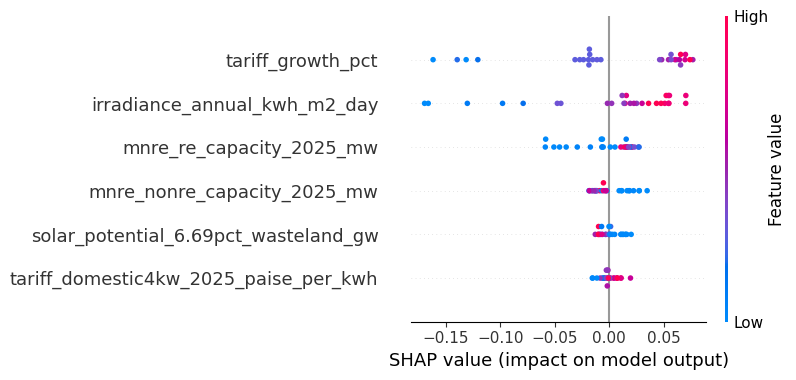

In [4]:
import shap

explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X6)
mean_abs_shap = np.abs(shap_values).mean(axis=0)

for feat, s in sorted(zip(features_6, mean_abs_shap), key=lambda x: -x[1]):
    print(f"  {feat:45s} {s:.4f}")

shap.summary_plot(shap_values, X6, show=True)

## Model B — Simple Linear Regression, 2 features (best result found previously)

In [5]:
features_2 = ["tariff_growth_pct", "irradiance_annual_kwh_m2_day"]
d2 = df[["state", "target_conversion_ratio"] + features_2].dropna()
X2, y2 = d2[features_2], d2["target_conversion_ratio"]

lr = LinearRegression()
scores_lr = cross_val_score(lr, X2, y2, cv=loo, scoring="neg_mean_absolute_error")
naive_mae_2 = np.mean(np.abs(y2 - y2.mean()))

print(f"n = {len(d2)}")
print(f"Linear Regression LOO-CV MAE: {-scores_lr.mean():.4f}")
print(f"Naive baseline MAE:           {naive_mae_2:.4f}")
print(f"Improvement over naive:       {(1 - (-scores_lr.mean())/naive_mae_2)*100:.1f}%")

lr.fit(X2, y2)
print()
print("Coefficients:", dict(zip(features_2, lr.coef_.round(4))))
print("In-sample R² (reference only, NOT the same as predictive power):", round(lr.score(X2, y2), 3))

n = 28
Linear Regression LOO-CV MAE: 0.1352
Naive baseline MAE:           0.1705
Improvement over naive:       20.7%

Coefficients: {'tariff_growth_pct': np.float64(1.6072), 'irradiance_annual_kwh_m2_day': np.float64(0.2504)}
In-sample R² (reference only, NOT the same as predictive power): 0.455


## Model comparison summary

| Model | Features | LOO-CV MAE | vs. Naive |
|---|---|---|---|
| **Linear Regression** | tariff_growth + irradiance | **~0.135** | **~-21%** |
| Random Forest | all 6 covariates | ~0.161 | ~-6% |

**Interpretation:** with only ~28-35 states, the simpler model generalizes better —
the Random Forest's extra features add noise, not signal, at this sample size.

**Report this honestly:**
- This is correlational, not causal (per guideline Section 7 requirements)
- n=28-35 is small; a 21% MAE improvement is suggestive, not conclusive
- Subsidy/tariff *level* and raw solar potential are consistently the *weakest*
  predictors — direct evidence against "subsidy amount alone" explaining adoption
- This is a single cross-sectional snapshot (23-Aug-2026) — whether these
  relationships hold requires a second aligned cross-section at a future date

## Next steps

- **Forecasting (Step 6 of guideline):** use `pmsg_snapshots_long.csv`'s dated
  national-level anchors with simple growth-rate extrapolation — do not fit
  ARIMA/SARIMAX on this few data points, it will overfit
- **Scenario simulation (Step 7):** the tariff_growth coefficient (~1.6) from
  Model B could plausibly drive a tariff-shock scenario simulation
- **State population data:** still needed for per-capita normalization —
  not yet collected